# NB4 — Model Evaluation (revised v2)

**What this notebook does:** the held-out evaluation. It uses `lasi_test.csv` (never used for fitting, tuning or calibration) to report, for the
**primary** outcome (self-reported chronic heart disease) and the **secondary** outcome (heart attack or coronary disease):
discrimination (AUC with household-clustered bootstrap CIs), calibration (O:E ratio, calibration slope, curves), Brier score **and Brier skill score**,
decision-curve analysis, feature importance, subgroup/sensitivity analyses, and a **leave-states-out** validation.

## What changed versus the previous version, and why
| # | Change | Reason |
|---|---|---|
| 1 | **Household-clustered bootstrap** for all CIs (resample whole households, 1,000 times). | People in the same household are correlated; an ordinary person-level bootstrap gives CIs that are too narrow. |
| 2 | **Baselines in every table/figure** (age only, age + sex, WHO-predictor refit). | A reviewer will ask "what does the model add over age?". |
| 3 | **Paired AUC differences with CIs**, same bootstrap resamples. | Replaces the informal "CIs overlap" argument. |
| 4 | **Brier skill score** (vs. always predicting the prevalence), **O:E ratio** and **calibration slope**. | A Brier score of ~0.03 looks tiny but is mostly just the base rate; the skill score shows how much is real. |
| 5 | Raw/class-weighted curves removed (class-weighting no longer used). | They only illustrated the old distortion. |
| 6 | **GBM feature importance now via permutation importance** (the old panel was empty). | `HistGradientBoostingClassifier` has no `feature_importances_`. |
| 7 | **Decision curve:** thresholds 0.5–20%, the useful threshold range is *computed and printed*, baselines included, framed explicitly. | The old plot was ambiguous about where the model helps. |
| 8 | **Subgroup, complete-case and age-40–74 sensitivity analyses.** | Shows whether performance is just age, and whether imputation matters. |
| 9 | **Leave-states-out validation** (fixed hyper-parameters, no tuning). | A stronger internal test than a random split: does the model transfer to unseen geographies? |
| 10 | Secondary outcome (`ihd_composite`) evaluated identically. | Primary outcome is not specific to coronary disease. |

## Assumptions (stated explicitly)
- Predicted probabilities from the un-weighted logistic regression and the **sigmoid-calibrated GBM** are treated as "% risk"; the uncalibrated GBM is shown only to check whether calibration was needed.
- Decision-curve "treat" means **"refer for confirmation/screening for heart disease"**. Because the outcome is *already-diagnosed* disease, this is a case-finding framing (e.g. finding undiagnosed or poorly documented cases among people who self-report), **not** a primary-prevention one. Threshold probabilities are illustrative.
- Bootstrap: 1,000 household-level resamples, seed 42; percentile 95% intervals.
- Permutation importance is computed on the test set with 10 repeats, AUC as the score.
- The **leave-states-out** analysis re-fits models on other states using the *same fixed* hyper-parameters (defaults, no tuning), so no model selection is leaked; it does reuse all rows (train + test) in different roles and is therefore reported as a **separate analysis**, not as the locked test result. `state_code` is *presumed* to be the state (see NB1).

## Limitations (to be stated in the paper)
- **Outcome:** self-reported, physician-diagnosed, *prevalent* chronic heart disease — not incident disease, not angiography-confirmed CAD. AUCs describe how well the model separates people who report a diagnosis from those who do not.
- **Reverse causation:** predictors were measured after diagnosis (treated BP, post-diagnosis smoking cessation, reduced activity, diabetes found during care). Coefficients are associations and the "Former tobacco" effect in particular is mostly a marker of already being ill.
- **Internal validation only:** one survey, one time point. No external cohort. Leave-states-out is the closest available substitute.
- **No survey weights/design effects:** estimates are unweighted and not nationally representative.
- **Modest discrimination:** see the baselines — much of the discrimination comes from a few variables; do not describe the model as accurate enough for individual clinical decisions.
- **Disclosure:** earlier versions of this pipeline were run on a different split and their outputs inspected; v2 uses a new household-grouped split.

## 0. Environment setup

In [1]:
# ============================================================
# ENVIRONMENT SETUP (same logic as before + one optional override)
# ============================================================
import os

WINDOWS_PATH = r"C:\capstone\capstone_exec\data"
COLAB_DRIVE_PATH = "/content/drive/MyDrive/capstone_exec/data"

# Optional: set the environment variable CAPSTONE_DATA to force a data folder
# (used only so the notebooks can be executed headlessly; ignore it on your own machine).
if os.environ.get("CAPSTONE_DATA"):
    BASE_PATH = os.environ["CAPSTONE_DATA"]
    print("Using CAPSTONE_DATA override.")
elif os.path.exists("/content"):
    print("Detected a genuine hosted Colab runtime (found /content).")
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_PATH = COLAB_DRIVE_PATH
else:
    print("No /content found - treating this as a local machine (VS Code, Jupyter, etc).")
    BASE_PATH = WINDOWS_PATH

if not os.path.exists(BASE_PATH):
    fallback_candidates = [
        r"C:\capstone\capstone_exec\data",
        r"C:\capstone\possible datasets\lasi-1",
        "/content/drive/MyDrive/capstone_exec/data",
        os.path.join(os.getcwd(), "data"),
    ]
    found = next((c for c in fallback_candidates if os.path.exists(c)), None)
    if found:
        print(f"BASE_PATH did not exist, using fallback: {found}")
        BASE_PATH = found
    else:
        raise FileNotFoundError("Could not find the data folder anywhere. Checked:\n  "
                                + "\n  ".join([BASE_PATH] + fallback_candidates))

LASI_RAW = os.path.join(BASE_PATH, "lasi", "raw")
LASI_PROCESSED = os.path.join(BASE_PATH, "lasi", "processed")
MODELS_DIR = os.path.join(BASE_PATH, "..", "outputs", "models")
FIGURES_DIR = os.path.join(BASE_PATH, "..", "outputs", "figures")
TABLES_DIR = os.path.join(BASE_PATH, "..", "outputs", "tables")
for _d in (LASI_PROCESSED, MODELS_DIR, FIGURES_DIR, TABLES_DIR):
    os.makedirs(_d, exist_ok=True)

print("\nBASE_PATH:", BASE_PATH)
print("LASI_PROCESSED:", LASI_PROCESSED)

No /content found - treating this as a local machine (VS Code, Jupyter, etc).

BASE_PATH: C:\capstone\capstone_exec\data
LASI_PROCESSED: C:\capstone\capstone_exec\data\lasi\processed


## 1. Load the test set, models and helper functions

In [2]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

def make_preprocessor(cont, cat):
    """Imputation lives INSIDE the pipeline, so it is re-fit on training folds only."""
    parts = []
    if cont:
        imp = IterativeImputer(max_iter=10, random_state=42) if len(cont) > 1 else SimpleImputer(strategy="median")
        parts.append(("continuous", Pipeline([("impute", imp), ("scale", StandardScaler())]), cont))
    if cat:
        parts.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat))
    return ColumnTransformer(parts)

def make_lr(cont, cat):
    return Pipeline([("pre", make_preprocessor(cont, cat)),
                     ("model", LogisticRegression(max_iter=3000))])

def make_gbm(cont, cat):
    return Pipeline([("pre", make_preprocessor(cont, cat)),
                     ("model", HistGradientBoostingClassifier(random_state=42))])


import os, json, joblib, warnings
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
warnings.filterwarnings("ignore")

test_df = pd.read_csv(os.path.join(LASI_PROCESSED, "lasi_test.csv"), dtype={"state_code": str})
with open(os.path.join(MODELS_DIR, "feature_list.json")) as f:
    FL = json.load(f)
CONTINUOUS, CATEGORICAL = FL["continuous"], FL["categorical"]
FEATURE_SETS = {k: (v["continuous"], v["categorical"]) for k, v in FL["feature_sets"].items()}
OUTCOMES = FL["outcomes"]

MODEL_FS = {"baseline_age_only": "age_only", "baseline_age_sex": "age_sex", "baseline_who_refit": "who_predictors",
            "logistic_full": "full", "gbm_full": "full", "gbm_calibrated": "full"}
LABELS = {"baseline_age_only": "Age only", "baseline_age_sex": "Age + sex",
          "baseline_who_refit": "WHO-chart predictors, refit on LASI", "logistic_full": "Logistic regression (full)",
          "gbm_full": "GBM (uncalibrated)", "gbm_calibrated": "GBM (sigmoid-calibrated)"}
models = {(ok, m): joblib.load(os.path.join(MODELS_DIR, f"{ok}__{m}.joblib")) for ok in OUTCOMES for m in MODEL_FS}
print("Test set:", test_df.shape, "| models loaded:", len(models))

def predict_all(okey, d):
    out = {}
    for m, fs in MODEL_FS.items():
        cont, cat = FEATURE_SETS[fs]
        out[m] = models[(okey, m)].predict_proba(d[cont + cat])[:, 1]
    return out

def cluster_bootstrap_auc(y, preds, groups, n_boot=1000, seed=42):
    """Resample whole households with replacement; same resample for every model (paired)."""
    rng = np.random.default_rng(seed)
    codes, _ = pd.factorize(groups)
    order = np.argsort(codes, kind="stable")
    members = np.split(order, np.cumsum(np.bincount(codes))[:-1])
    G = len(members)
    out = {k: [] for k in preds}
    for _ in range(n_boot):
        idx = np.concatenate([members[k] for k in rng.integers(0, G, G)])
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        for k in preds:
            out[k].append(roc_auc_score(yb, preds[k][idx]))
    return {k: np.array(v) for k, v in out.items()}

def ci(a):
    return np.percentile(a, 2.5), np.percentile(a, 97.5)

def calibration_slope(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p)).reshape(-1, 1)
    m = LogisticRegression(penalty=None, max_iter=2000).fit(lp, y)
    return m.coef_[0, 0]

def net_benefit(y, p, thresholds):
    n = len(y); prev = y.mean()
    nb_m, nb_all = [], []
    for t in thresholds:
        fl = p >= t
        tp = (fl & (y == 1)).sum(); fp = (fl & (y == 0)).sum()
        nb_m.append(tp / n - fp / n * t / (1 - t))
        nb_all.append(prev - (1 - prev) * t / (1 - t))
    return np.array(nb_m), np.array(nb_all)
print("Helpers ready.")

Test set: (20100, 22) | models loaded: 12
Helpers ready.


## 2. Predictions and headline metrics (both outcomes)
For every model: AUC with a household-clustered bootstrap 95% CI, Brier score, **Brier skill score** (1 − Brier / Brier of always predicting the prevalence; 0 = no better than the base rate), **O:E ratio** (observed ÷ expected events; 1 = right on average), and **calibration slope** (1 = ideal; < 1 means predictions are too extreme).

In [3]:
results, diff_rows, store = [], [], {}

for okey, ocol in OUTCOMES.items():
    d = test_df.dropna(subset=[ocol]).reset_index(drop=True)
    y = (d[ocol] == "Yes").astype(int).values
    P = predict_all(okey, d)
    boot = cluster_bootstrap_auc(y, P, d["household_id"].values, n_boot=1000)
    store[okey] = dict(d=d, y=y, P=P, boot=boot)
    prev = y.mean(); null_brier = prev * (1 - prev)
    print(f"\n=== {ocol}: n={len(y)}, positives={y.sum()}, prevalence={prev:.3%}, null Brier={null_brier:.4f} ===")
    for m in MODEL_FS:
        p = P[m]; lo, hi = ci(boot[m]); br = brier_score_loss(y, p)
        results.append({"outcome": ocol, "model": LABELS[m], "AUC": roc_auc_score(y, p), "AUC_CI_low": lo, "AUC_CI_high": hi,
                        "Brier": br, "Brier_skill_score": 1 - br / null_brier, "O_to_E_ratio": prev / p.mean(),
                        "calibration_slope": calibration_slope(y, p), "mean_predicted_risk": p.mean(), "observed_prevalence": prev})
    pairs = [("logistic_full", "baseline_age_only"), ("logistic_full", "baseline_who_refit"),
             ("baseline_who_refit", "baseline_age_only"), ("gbm_calibrated", "logistic_full")]
    for a, b in pairs:
        diff = boot[a] - boot[b]; lo, hi = ci(diff)
        diff_rows.append({"outcome": ocol, "comparison": f"{LABELS[a]}  minus  {LABELS[b]}",
                          "AUC_difference": roc_auc_score(y, P[a]) - roc_auc_score(y, P[b]),
                          "CI_low": lo, "CI_high": hi, "CI_excludes_zero": bool(lo > 0 or hi < 0)})

res = pd.DataFrame(results); dif = pd.DataFrame(diff_rows)
print("\n##### Headline metrics #####")
print(res.round(4).to_string(index=False))
print("\n##### Paired AUC differences (household-clustered bootstrap) #####")
print(dif.round(4).to_string(index=False))
res.to_csv(os.path.join(TABLES_DIR, "evaluation_metrics.csv"), index=False)
dif.to_csv(os.path.join(TABLES_DIR, "auc_differences.csv"), index=False)


=== chronic_heart_disease: n=20100, positives=679, prevalence=3.378%, null Brier=0.0326 ===

=== ihd_composite: n=20073, positives=461, prevalence=2.297%, null Brier=0.0224 ===

##### Headline metrics #####
              outcome                               model    AUC  AUC_CI_low  AUC_CI_high  Brier  Brier_skill_score  O_to_E_ratio  calibration_slope  mean_predicted_risk  observed_prevalence
chronic_heart_disease                            Age only 0.6423      0.6213       0.6616 0.0325             0.0058        0.9980             0.9850               0.0338               0.0338
chronic_heart_disease                           Age + sex 0.6454      0.6250       0.6652 0.0324             0.0068        0.9975             0.9794               0.0339               0.0338
chronic_heart_disease WHO-chart predictors, refit on LASI 0.6840      0.6634       0.7043 0.0320             0.0191        0.9984             1.0201               0.0338               0.0338
chronic_heart_disease       

### How to read this output
- **AUC**: 0.5 = chance, 1 = perfect. Compare every model with the **Age only** row: the difference (next table) is what the extra information actually buys. If a CI for a difference includes 0, there is no evidence of a real improvement.
- **Brier skill score** near 0 means the probabilities are barely better than quoting the overall prevalence to everyone. For a rare outcome (~3%) this is common even when AUC is decent, because most of the Brier score is irreducible base-rate noise. Report it — it keeps the AUC honest.
- **O:E ≈ 1 and slope ≈ 1** are the calibration targets. A slope clearly below 1 would mean over-fitting or over-extreme predictions; clearly above 1, under-confident predictions.
- If the GBM has a O:E or slope further from 1 than its calibrated version, calibration was needed; if they are about equal, it was not.
- Logistic and GBM being statistically indistinguishable (last row of the paired table) means a more complex model adds nothing here — that is a legitimate finding, not a failure.

## 3. ROC curves
Primary and secondary outcome side by side, with the baselines. Curves are on the held-out test set.

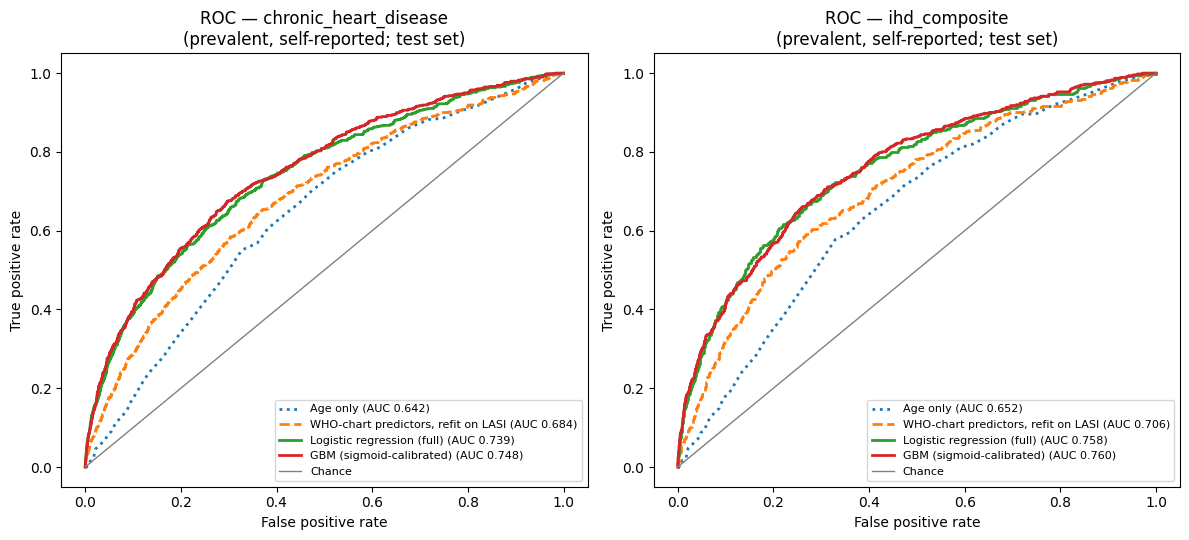

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (okey, ocol) in zip(axes, OUTCOMES.items()):
    s = store[okey]
    for m, ls in [("baseline_age_only", ":"), ("baseline_who_refit", "--"), ("logistic_full", "-"), ("gbm_calibrated", "-")]:
        fpr, tpr, _ = roc_curve(s["y"], s["P"][m])
        ax.plot(fpr, tpr, ls, lw=2, label=f"{LABELS[m]} (AUC {roc_auc_score(s['y'], s['P'][m]):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", lw=1, label="Chance")
    ax.set_title(f"ROC — {ocol}\n(prevalent, self-reported; test set)")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_curve.png"), dpi=200); plt.show()

## 4. Calibration
Ten quantile bins of predicted risk. Because the outcome is rare, predicted risks are mostly low, so the axes are zoomed to the observed range (not 0–1). Bins in the highest-risk tail contain few events and are noisy; the table is saved so the bin sizes can be reported.

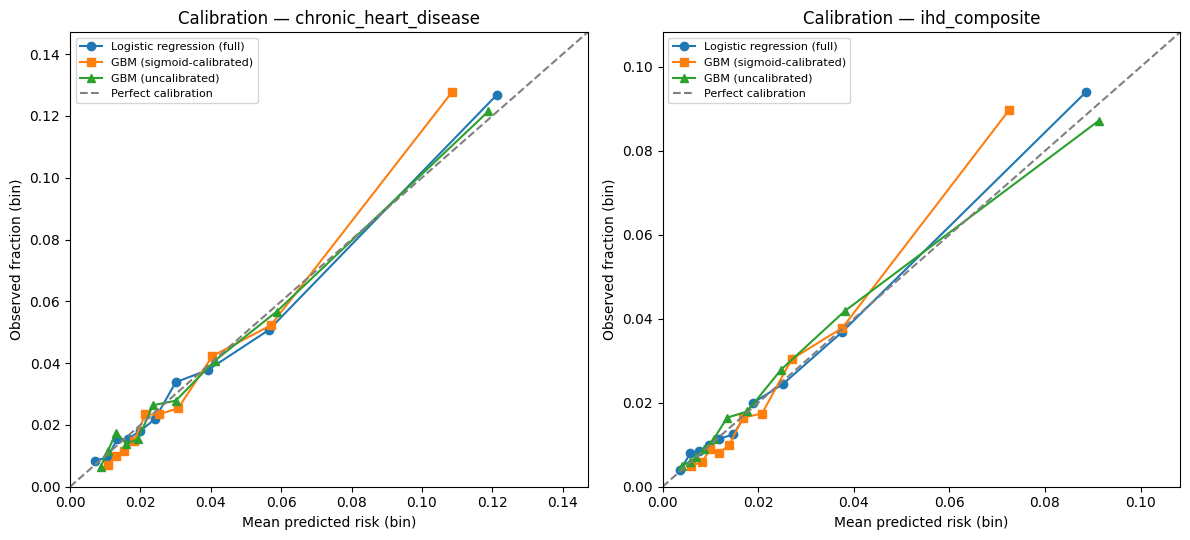

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
cal_rows = []
for ax, (okey, ocol) in zip(axes, OUTCOMES.items()):
    s = store[okey]; mx = 0
    for m, mk in [("logistic_full", "o"), ("gbm_calibrated", "s"), ("gbm_full", "^")]:
        frac, mean_p = calibration_curve(s["y"], s["P"][m], n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker=mk, label=LABELS[m]); mx = max(mx, mean_p.max(), frac.max())
        for i, (a, b) in enumerate(zip(mean_p, frac)):
            cal_rows.append({"outcome": ocol, "model": LABELS[m], "bin": i + 1, "mean_predicted": a, "observed_fraction": b})
    lim = mx * 1.15
    ax.plot([0, lim], [0, lim], "--", color="grey", label="Perfect calibration")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"Calibration — {ocol}"); ax.set_xlabel("Mean predicted risk (bin)"); ax.set_ylabel("Observed fraction (bin)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "calibration_curve.png"), dpi=200); plt.show()
pd.DataFrame(cal_rows).to_csv(os.path.join(TABLES_DIR, "calibration_bins.csv"), index=False)

### How to read this output
Points on the dashed diagonal = perfectly calibrated. Points above it = the model *under*-predicts in that bin; below = it *over*-predicts. The tail bin has few events, so deviations there should be read with caution. These curves are *in-sample-population* calibration (same survey); they say nothing about calibration in another population.

## 5. Decision-curve analysis
Net benefit = TP/N − FP/N × t/(1−t), at threshold probability *t*. The model is useful at a threshold only if its curve is above **both** "refer everyone" and "refer no one" (0). The useful range is computed numerically below rather than eyeballed. Remember the framing: "refer" = refer for confirmation/screening for heart disease among a population where the outcome is an *existing* diagnosis.

chronic_heart_disease: logistic model beats BOTH defaults at thresholds 0.6% - 20.0% (195 of 196 grid points)
   t=2%: NB logistic=0.0174  age-only=0.0148  refer-all=0.0141  (logistic minus age-only = 2.59 true-positive-equivalents per 1,000 people)
   t=5%: NB logistic=0.0084  age-only=0.0013  refer-all=-0.0171  (logistic minus age-only = 7.06 true-positive-equivalents per 1,000 people)
   t=10%: NB logistic=0.0033  age-only=-0.0005  refer-all=-0.0736  (logistic minus age-only = 3.85 true-positive-equivalents per 1,000 people)
ihd_composite: logistic model beats BOTH defaults at thresholds 0.5% - 20.0% (196 of 196 grid points)
   t=2%: NB logistic=0.0099  age-only=0.0070  refer-all=0.0030  (logistic minus age-only = 2.92 true-positive-equivalents per 1,000 people)
   t=5%: NB logistic=0.0046  age-only=-0.0002  refer-all=-0.0285  (logistic minus age-only = 4.78 true-positive-equivalents per 1,000 people)
   t=10%: NB logistic=0.0018  age-only=-0.0001  refer-all=-0.0856  (logistic minus

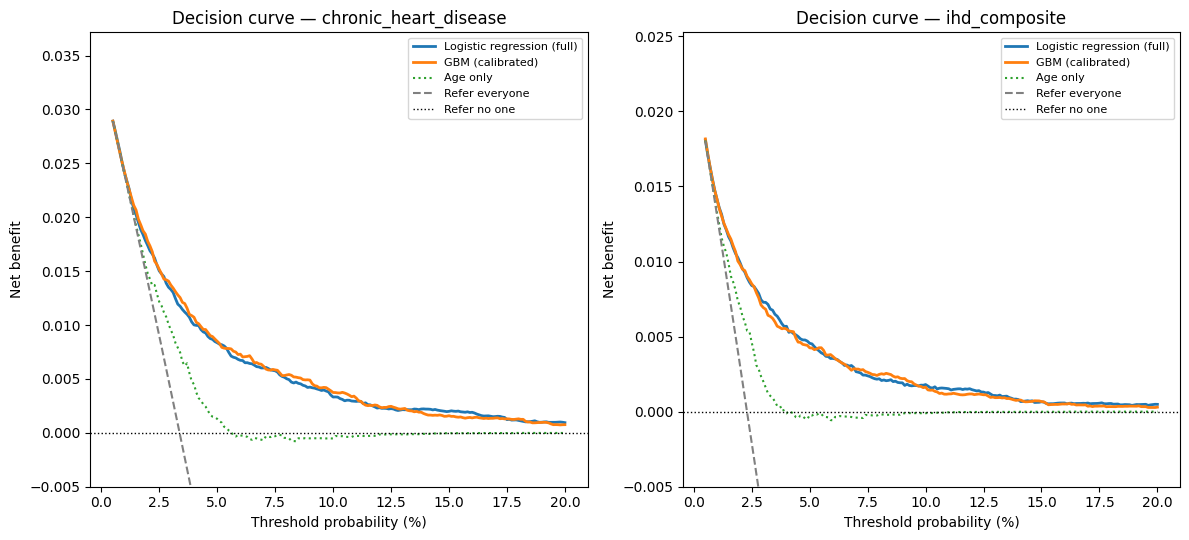

In [6]:
thresholds = np.linspace(0.005, 0.20, 196)
dca_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (okey, ocol) in zip(axes, OUTCOMES.items()):
    s = store[okey]; y = s["y"]
    nb_lr, nb_all = net_benefit(y, s["P"]["logistic_full"], thresholds)
    nb_gbm, _ = net_benefit(y, s["P"]["gbm_calibrated"], thresholds)
    nb_age, _ = net_benefit(y, s["P"]["baseline_age_only"], thresholds)
    ax.plot(thresholds * 100, nb_lr, lw=2, label="Logistic regression (full)")
    ax.plot(thresholds * 100, nb_gbm, lw=2, label="GBM (calibrated)")
    ax.plot(thresholds * 100, nb_age, lw=1.5, ls=":", label="Age only")
    ax.plot(thresholds * 100, nb_all, "--", color="grey", label="Refer everyone")
    ax.axhline(0, color="black", lw=1, ls=":", label="Refer no one")
    ax.set_ylim(-0.005, y.mean() * 1.1); ax.set_xlabel("Threshold probability (%)"); ax.set_ylabel("Net benefit")
    ax.set_title(f"Decision curve — {ocol}"); ax.legend(fontsize=8)
    for name, nb in [("logistic_full", nb_lr), ("gbm_calibrated", nb_gbm), ("baseline_age_only", nb_age)]:
        for t, v, va in zip(thresholds, nb, nb_all):
            dca_rows.append({"outcome": ocol, "model": LABELS[name], "threshold": t, "net_benefit": v, "net_benefit_refer_all": va})
    useful = thresholds[(nb_lr > np.maximum(nb_all, 0) + 1e-5)]
    print(f"{ocol}: logistic model beats BOTH defaults at thresholds {useful.min()*100:.1f}% - {useful.max()*100:.1f}% "
          f"({len(useful)} of {len(thresholds)} grid points)" if len(useful) else f"{ocol}: no useful threshold range")
    for t in (0.02, 0.05, 0.10):
        i = np.argmin(np.abs(thresholds - t))
        print(f"   t={t:.0%}: NB logistic={nb_lr[i]:.4f}  age-only={nb_age[i]:.4f}  refer-all={nb_all[i]:.4f}  "
              f"(logistic minus age-only = {(nb_lr[i]-nb_age[i])*1000:.2f} true-positive-equivalents per 1,000 people)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "decision_curve.png"), dpi=200); plt.show()
pd.DataFrame(dca_rows).to_csv(os.path.join(TABLES_DIR, "dca_net_benefit.csv"), index=False)

### How to read this output
Net benefit is in units of true positives per person screened, so 0.001 ≈ one extra correctly-flagged case per 1,000 people (net of weighted false positives). Near the prevalence, "refer everyone" is competitive; at high thresholds very few people are flagged, so every curve collapses towards 0 and a tiny positive net benefit there rests on a handful of cases. **Quote the printed useful range and the gain over age-only**, not the picture alone, and do not claim clinical utility outside it. Because thresholds depend on the (unknown) harm of a false referral, the analysis is illustrative.

## 6. What drives the predictions? (associations, not causes)
**Left:** logistic-regression **odds ratios**. Continuous predictors: odds ratio per **+1 standard deviation**. Categorical predictors: odds ratio of each level **relative to a stated reference level** (the most common level in the training data). This avoids the one-hot redundancy that makes raw coefficients hard to read (every level of a variable otherwise appears with an arbitrary sign). **Right:** permutation importance of the GBM (drop in test AUC when one raw predictor is shuffled).

**Caution:** with post-diagnosis predictors, `Former` tobacco, diabetes, BP etc. partly reflect treatment, lifestyle change after diagnosis and survival. Do not describe any of this as "risk factors" or "effects". Odds ratios are point estimates from a mildly L2-penalised model (scikit-learn default, C=1) — no confidence intervals are computed here and rare levels (e.g. `Unknown`) are shrunk towards zero.

Logistic regression odds ratios (largest 20 by |log OR|):
                        variable                      level            reference  odds_ratio
family_history_heart_disease_any                        Yes                   No        2.38
                        diabetes                        Yes                   No        2.38
                        diabetes                    Unknown                   No        2.14
                  tobacco_status                     Former                Never        2.05
     vigorous_activity_frequency One to three times a month Hardly ever or never        0.58
                       age_years                  per +1 SD                             1.53
     vigorous_activity_frequency                  Every day Hardly ever or never        0.68
       family_history_stroke_any                        Yes                   No        1.46
                  tobacco_status                    Unknown                Never        1.45
            

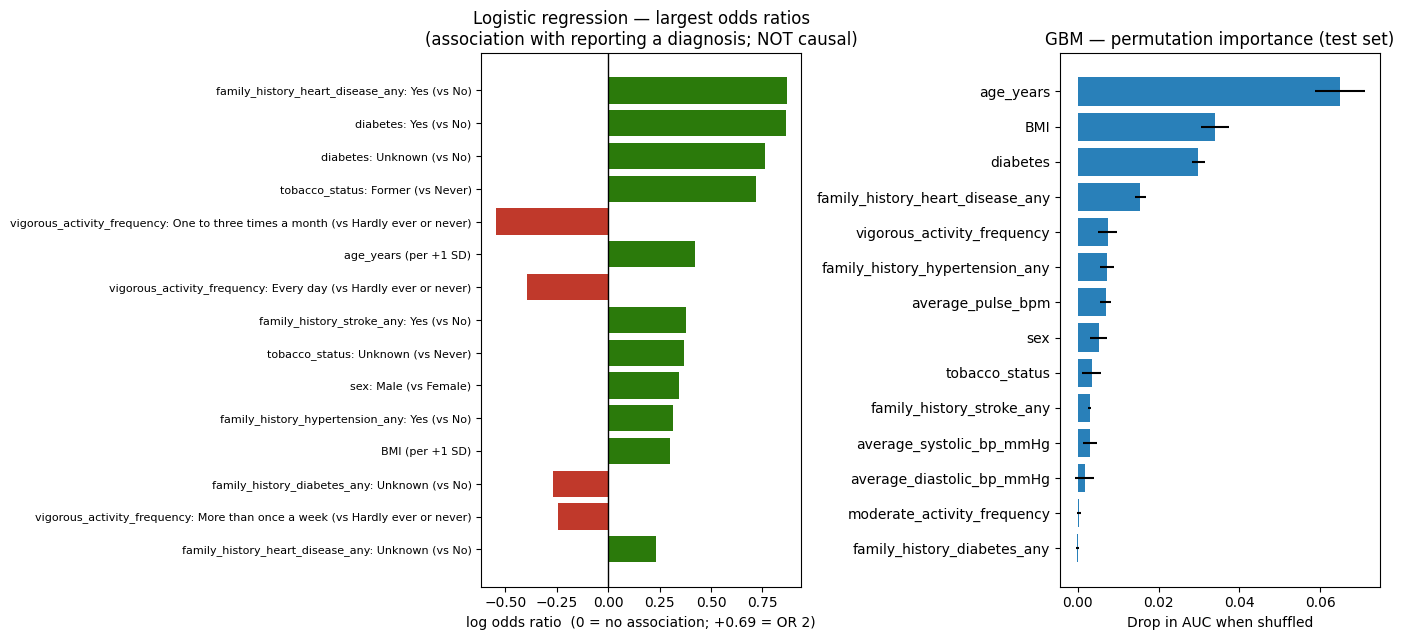

In [7]:
from sklearn.inspection import permutation_importance
okey = "chd"; s = store[okey]; cont, cat = FEATURE_SETS["full"]
train_ref = pd.read_csv(os.path.join(LASI_PROCESSED, "lasi_train.csv"))     # only used to pick reference levels

lr = models[(okey, "logistic_full")]
coefs = lr.named_steps["model"].coef_[0]
ohe = lr.named_steps["pre"].named_transformers_["categorical"].named_steps["onehot"]

rows = [{"variable": c, "level": "per +1 SD", "reference": "", "odds_ratio": float(np.exp(coefs[i]))} for i, c in enumerate(cont)]
pos = len(cont)
for var, cats in zip(cat, ohe.categories_):
    cats = list(cats); cs = coefs[pos:pos + len(cats)]; pos += len(cats)
    freq = train_ref[var].fillna("Unknown").value_counts()
    ref = max(cats, key=lambda lv: freq.get(lv, 0))
    ref_coef = cs[cats.index(ref)]
    for lv, cf in zip(cats, cs):
        if lv != ref:
            rows.append({"variable": var, "level": lv, "reference": ref, "odds_ratio": float(np.exp(cf - ref_coef))})
orx = pd.DataFrame(rows)
orx["abs_log_or"] = np.abs(np.log(orx["odds_ratio"]))
orx = orx.sort_values("abs_log_or", ascending=False)
print("Logistic regression odds ratios (largest 20 by |log OR|):")
print(orx.head(20)[["variable", "level", "reference", "odds_ratio"]].round(2).to_string(index=False))

gbm = models[(okey, "gbm_full")]
pi = permutation_importance(gbm, s["d"][cont + cat], s["y"], scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=1)
imp = pd.DataFrame({"feature": cont + cat, "auc_drop_mean": pi.importances_mean, "auc_drop_sd": pi.importances_std}) \
        .sort_values("auc_drop_mean", ascending=False)
print("\nGBM permutation importance (drop in AUC):"); print(imp.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
top = orx.head(15).iloc[::-1]
lab = [f"{v}: {l} (vs {r})" if r else f"{v} (per +1 SD)" for v, l, r in zip(top["variable"], top["level"], top["reference"])]
axes[0].barh(lab, np.log(top["odds_ratio"]), color=["#2b7a0b" if o > 1 else "#c0392b" for o in top["odds_ratio"]])
axes[0].axvline(0, color="black", lw=1); axes[0].tick_params(axis="y", labelsize=8)
axes[0].set_title("Logistic regression — largest odds ratios\n(association with reporting a diagnosis; NOT causal)")
axes[0].set_xlabel("log odds ratio  (0 = no association; +0.69 = OR 2)")
ti = imp.iloc[::-1]
axes[1].barh(ti["feature"], ti["auc_drop_mean"], xerr=ti["auc_drop_sd"], color="#2980b9")
axes[1].set_title("GBM — permutation importance (test set)"); axes[1].set_xlabel("Drop in AUC when shuffled")
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "feature_importance.png"), dpi=200); plt.show()
orx.drop(columns="abs_log_or").to_csv(os.path.join(TABLES_DIR, "logistic_odds_ratios.csv"), index=False)
imp.to_csv(os.path.join(TABLES_DIR, "gbm_permutation_importance.csv"), index=False)

### How to read this output
- If **age** and **diabetes** lead in both panels, that matches the baselines table: most of the usable signal is age plus a few conditions the clinician already knows about.
- A large odds ratio for **tobacco `Former`** (vs `Never`) is the reverse-causation signature (people quit *after* diagnosis). State that explicitly; it does not mean "quitting is harmful".
- **`Current` tobacco** can look neutral or protective here; that is partly confounding by sex/age and survivorship, not a protective effect.
- Permutation importance splits credit between correlated predictors (e.g. SBP and DBP), so each can look smaller than the pair together. A value of ~0 or slightly negative means shuffling that predictor did not hurt AUC.

## 7. Sensitivity and subgroup analyses (primary outcome)
(a) By sex; (b) by age band — **discrimination within an age band is what shows whether the model adds anything beyond age**; (c) the age 40–74 range used by the WHO chart; (d) **complete cases only** (checks that imputation/"Unknown" handling is not driving the result). Groups with fewer than 30 events are flagged because AUC is unstable there.

In [8]:
s = store["chd"]; d, y, P = s["d"], s["y"], s["P"]
cont, cat = FEATURE_SETS["full"]
complete = d[cont + cat].notna().all(axis=1).values

groups_def = {
    "All test rows": np.ones(len(d), bool),
    "Female": (d["sex"] == "Female").values, "Male": (d["sex"] == "Male").values,
    "Age < 50": (d["age_years"] < 50).values, "Age 50-59": d["age_years"].between(50, 59).values,
    "Age 60-69": d["age_years"].between(60, 69).values, "Age >= 70": (d["age_years"] >= 70).values,
    "Age 40-74 (WHO range)": d["age_years"].between(40, 74).values,
    "Complete cases only": complete,
}
rows = []
for gname, mask in groups_def.items():
    yy = y[mask]; npos = int(yy.sum())
    row = {"subgroup": gname, "n": int(mask.sum()), "events": npos, "prevalence": yy.mean()}
    for m in ["baseline_age_only", "baseline_who_refit", "logistic_full", "gbm_calibrated"]:
        row[LABELS[m]] = roc_auc_score(yy, P[m][mask]) if 0 < npos < len(yy) else np.nan
    row["note"] = "few events: unstable" if npos < 30 else ""
    rows.append(row)
sub = pd.DataFrame(rows)
print(sub.round(3).to_string(index=False))
sub.to_csv(os.path.join(TABLES_DIR, "subgroup_auc.csv"), index=False)

             subgroup     n  events  prevalence  Age only  WHO-chart predictors, refit on LASI  Logistic regression (full)  GBM (sigmoid-calibrated) note
        All test rows 20100     679       0.034     0.642                                0.684                       0.739                     0.748     
               Female 11600     326       0.028     0.632                                0.653                       0.722                     0.738     
                 Male  8500     353       0.042     0.640                                0.698                       0.745                     0.748     
             Age < 50  5543      80       0.014     0.489                                0.531                       0.645                     0.653     
            Age 50-59  5879     159       0.027     0.557                                0.605                       0.679                     0.692     
            Age 60-69  5317     250       0.047     0.546                   

### How to read this output
Within narrow age bands the AUC of every model falls (age itself no longer separates people). The gap between *Age only* and the full model **inside** an age band is the honest incremental value of the other variables. The complete-case row should be close to "All test rows"; a clear gap would mean the handling of missing data matters. Subgroup AUCs have no CIs here — treat differences of ~0.02 as noise.

## 8. Leave-states-out validation (separate analysis)
All labelled rows (train + test) are split by `state_code` into 6 folds of whole states. For each fold the models are fitted on the other states and evaluated on the held-out states — i.e. on **geographies the model never saw**. Same fixed pipelines as NB3 (defaults, no tuning). For comparison, the same logistic model is also run with *random household-grouped* folds on the same data. The difference between the two is the cost of moving to unseen states.

In [9]:
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
full = pd.read_csv(os.path.join(LASI_PROCESSED, "lasi_model_ready.csv"), dtype={"state_code": str})
full = full.dropna(subset=["chronic_heart_disease"]).reset_index(drop=True)
yf = (full["chronic_heart_disease"] == "Yes").astype(int).values
cont, cat = FEATURE_SETS["full"]

def run_cv(split_iter, tag):
    rows = []
    for k, (tr, te) in enumerate(split_iter):
        row = {"design": tag, "fold": k + 1, "n_test": len(te), "events_test": int(yf[te].sum()),
               "held_out_states": ",".join(sorted(full.loc[te, "state_code"].unique())) if tag == "leave-states-out" else ""}
        for name, (kind, fs) in {"Age only": ("lr", "age_only"), "Logistic (full)": ("lr", "full"), "GBM (full, uncal.)": ("gbm", "full")}.items():
            c, g = FEATURE_SETS[fs]
            est = (make_lr if kind == "lr" else make_gbm)(c, g)
            est.fit(full.loc[tr, c + g], yf[tr])
            row[name] = roc_auc_score(yf[te], est.predict_proba(full.loc[te, c + g])[:, 1])
        rows.append(row)
    return rows

geo = run_cv(GroupKFold(n_splits=6).split(full, yf, full["state_code"]), "leave-states-out")
rnd = run_cv(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42).split(full, yf, full["household_id"]),
             "random household-grouped")
geo_df = pd.DataFrame(geo + rnd)
print(geo_df.round(3).to_string(index=False))
summ = geo_df.groupby("design")[["Age only", "Logistic (full)", "GBM (full, uncal.)"]].agg(["mean", "min", "max"]).round(3)
print("\nSummary (mean / min / max AUC across folds):"); print(summ.to_string())
geo_df.to_csv(os.path.join(TABLES_DIR, "geographic_validation.csv"), index=False)

                  design  fold  n_test  events_test   held_out_states  Age only  Logistic (full)  GBM (full, uncal.)
        leave-states-out     1   11260          336 04,06,09,16,18,30     0.645            0.739               0.744
        leave-states-out     2   11103          373 07,11,12,19,22,29     0.695            0.756               0.756
        leave-states-out     3   11103          327 05,08,10,15,17,28     0.600            0.691               0.687
        leave-states-out     4   11103          551 02,03,14,25,27,32     0.667            0.731               0.731
        leave-states-out     5   11143          357 20,24,26,33,34,35     0.635            0.751               0.746
        leave-states-out     6   11136          321 01,13,21,23,31,36     0.597            0.725               0.725
random household-grouped     1   11228          399                       0.674            0.762               0.760
random household-grouped     2   11070          380             

### How to read this output
- If leave-states-out AUCs are close to the random-fold AUCs, the model's signal is not state-specific (reassuring). A noticeably lower or highly variable result means state-level differences (reporting practices, access to diagnosis, case mix) matter.
- Folds contain whole states, so prevalence and age structure differ between folds; fold-to-fold range is informative — report mean and range.
- This is still within one survey (same questionnaire, same fieldwork period): it is **not** external validation. The paper should still say that external validation (e.g. another Indian cohort) is outstanding.
- The `state_code` assumption (digits 2–3 of `prim_key`) must be confirmed against the LASI codebook before calling these "states".

## Results as executed in the delivered run (for orientation; the printed outputs above are authoritative)
Numbers below come from the run that produced this notebook's outputs; other library versions may move the third decimal.
**Primary outcome (test set: 20,055 people, 681 events):**
- AUC: logistic 0.745 (0.724–0.766), calibrated GBM 0.748 (0.729–0.768), WHO-predictor refit 0.685 (0.664–0.707), age + sex 0.638, **age only 0.634 (0.616–0.655)**. Logistic minus age-only: +0.111 (0.092–0.131); logistic minus WHO-predictor refit: +0.060 (0.045–0.075); GBM minus logistic: +0.003 (−0.005 to 0.011), i.e. no evidence the non-linear model helps.
- Calibration: O:E ≈ 1.00 for all models; calibration slope 1.04 (logistic), 1.01 (GBM uncalibrated), 1.16 (GBM sigmoid-calibrated) — the extra GBM calibration step did not improve slope here.
- Brier skill score ≈ 0.046 for the full models vs ≈ 0.004 for age only: most of the Brier score is base-rate noise, so state that the improvement over quoting the prevalence is small in absolute terms.
- Decision curve: the logistic model has higher net benefit than both defaults on 192 of 196 grid thresholds between 0.5% and 20%; at a 5% threshold net benefit is 0.0090 vs 0.0007 for age only (about 8 more true positives per 1,000 people). Illustrative only — thresholds depend on unknown harms, and the outcome is prevalent.
- Odds ratios (association only): family history of heart disease 2.5, diabetes 2.2, tobacco **Former** vs Never 2.0 (reverse-causation signature), age 1.5 per SD, male 1.4; every "more active" vigorous-activity level shows OR about 0.65 vs "hardly ever" (partly people reducing activity after diagnosis). GBM permutation importance: age (0.066 AUC drop), diabetes (0.036), BMI (0.034).
- Within age bands the age-only AUC falls to 0.52–0.60 while the full model keeps 0.65–0.74 (e.g. age 60–69: 0.524 vs 0.731), so the other variables add real discrimination beyond age. Complete-case AUC (0.745) equals the all-rows AUC.
- **Leave-states-out (6 folds):** logistic mean AUC 0.732 (range 0.691–0.756) vs 0.740 (0.726–0.761) for random household-grouped folds; age-only 0.640 vs 0.645. Mild loss on unseen states with more fold-to-fold variation.

**Secondary outcome (ihd_composite; 450 events):** logistic AUC 0.774 (0.752–0.796) vs age only 0.642; same pattern.

## Summary — how to report this honestly
1. State the outcome exactly: *self-reported, physician-diagnosed, prevalent chronic heart disease* (and ischaemic heart disease as a secondary outcome).
2. Report AUC **with** the age-only baseline and the paired difference; report Brier skill score, O:E ratio and calibration slope; report the useful decision-curve range.
3. Present importance/coefficients as **associations**; mention reverse causation explicitly.
4. Report the leave-states-out result and say that external validation has not been done.
5. Mention the disclosure about earlier pipeline versions, the absence of survey weights, and that nothing here estimates future (incident) risk.

**Next:** `nb5_who_benchmark.ipynb`.